# Antiguide Propagation

The term Antiguide refers to a 3 layer guide with a central refractive index of lower value than it's outer refractive index.  Such guides do not support guided modes and can only propagate energy in the radiation field.  Since the slab package calculates the radiation field, it is well-suited to modeling this guide.  

This tutorial first calculates the field induced such a guide by our standard example input field.  It then introduces procedures for calculating leaky modes and the leaky field of the guide, and shows that the leaky field well-approximated the true field for this guide.  Additionally, it highlights some of the animation capabilities of the package.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from slab2 import Slab, Propagator
from slab2.contours import real_contour

from scipy.optimize import newton
from scipy.integrate import quad
from IPython.display import Video, HTML

plt.style.use('dark_background')
%matplotlib widget

In [2]:
A = Slab(Ts=[4,2,4], ns=[1.44, 1, 1.44], wl=1e-6)


In [3]:
half_width = 1.75
shift = .25
amplitude = 1.25

Lx = -half_width + shift
Rx = half_width + shift

def quadratic_piecewise(x):
    x = np.array(x, dtype=float)
    conds = [(x < Lx), ((Lx <= x)*(x <= Rx)), (x > Rx)]
    funcs = [lambda x: 0, lambda x: amplitude * (1 - ((x - shift) / half_width)**2), lambda x: 0]
    return np.piecewise(x, conds, funcs)

def quadratic_piecewise2d(x, zs=None, wavenumber=A.K0):
    fx = quadratic_piecewise(x)
    fz = np.exp(1j * wavenumber * zs)
    return np.outer(fz, fx)

f0 = quadratic_piecewise
F0 = quadratic_piecewise2d


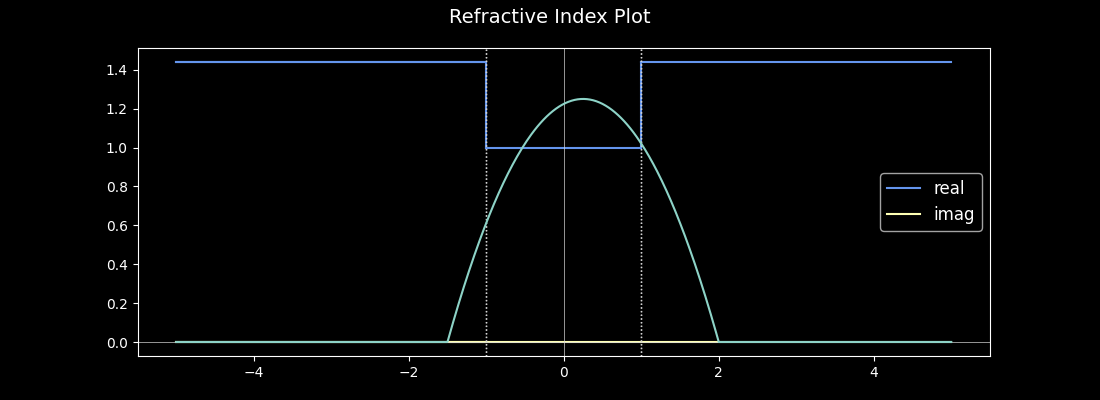

In [4]:
A.plot_refractive_index()
A.add_1d_plot(f0)

In [5]:
P = Propagator(A, f0=f0, window=[Lx,Rx])

/home/pv/local/slab2/propagator.py:696: UserWarning: Structure does not support guided modes.  Setting guided field to zero function.
  warn("Structure does not support guided modes.  Setting guided \


In [6]:
P.add_contour(real_contour(.00001, A.Z_evanescent, 350))

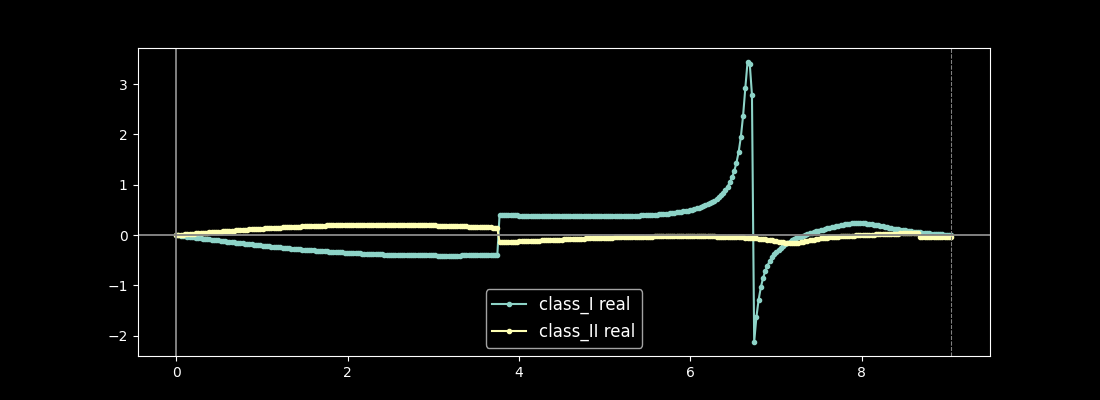

In [7]:
P.plot_transform();

In [8]:
P.add_contour(real_contour(6.55, 6.85, 70))

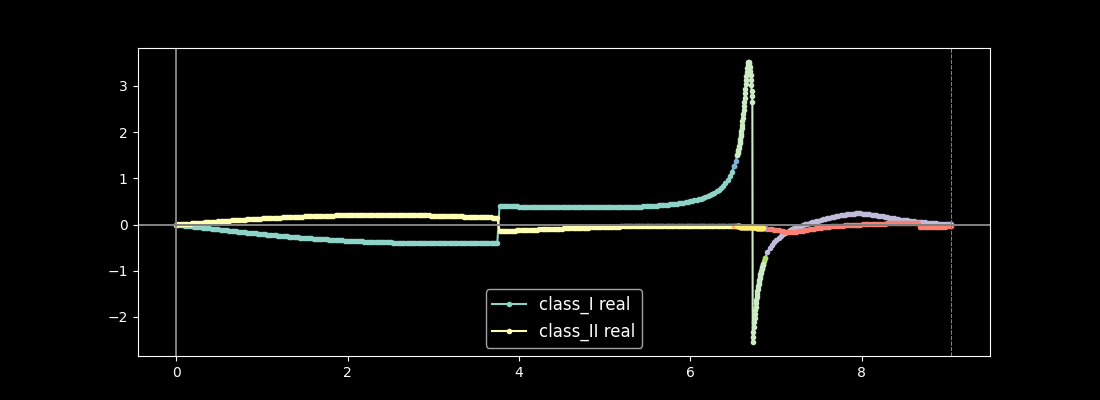

In [9]:
P.plot_transform();

In [10]:
P.add_contour(real_contour(A.Z_evanescent, 2*A.Z_evanescent, 150))

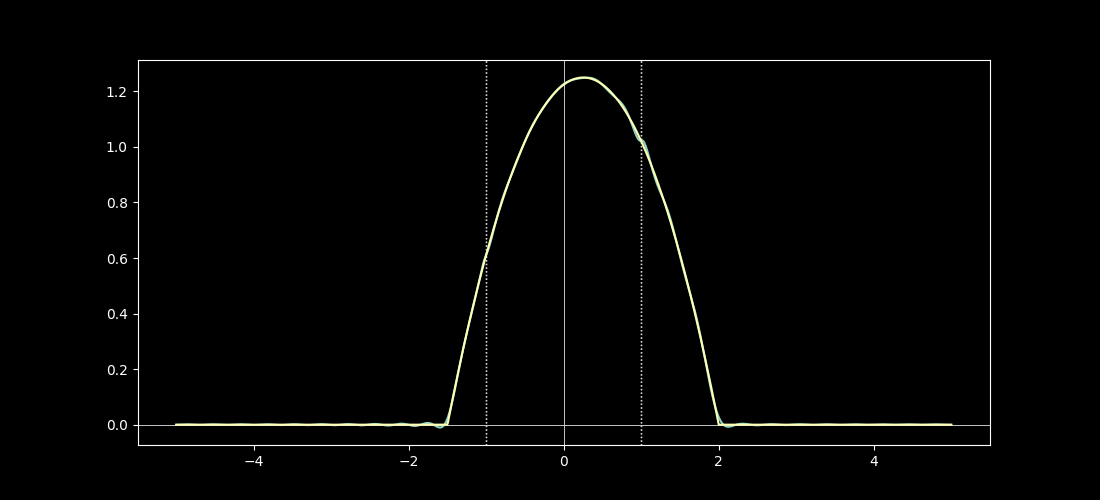

In [11]:
A.plot_field_1d(P);
A.add_1d_plot(f0);

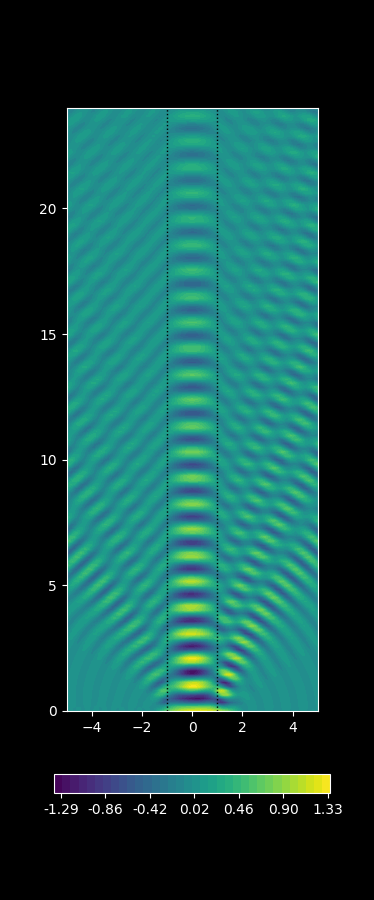

In [12]:
A.plot_field_2d(P, zmax=24);

## Leaky Modes

This pure radiation field should be well-approximated by the leaky field (unless the SDP contribution is also significant).

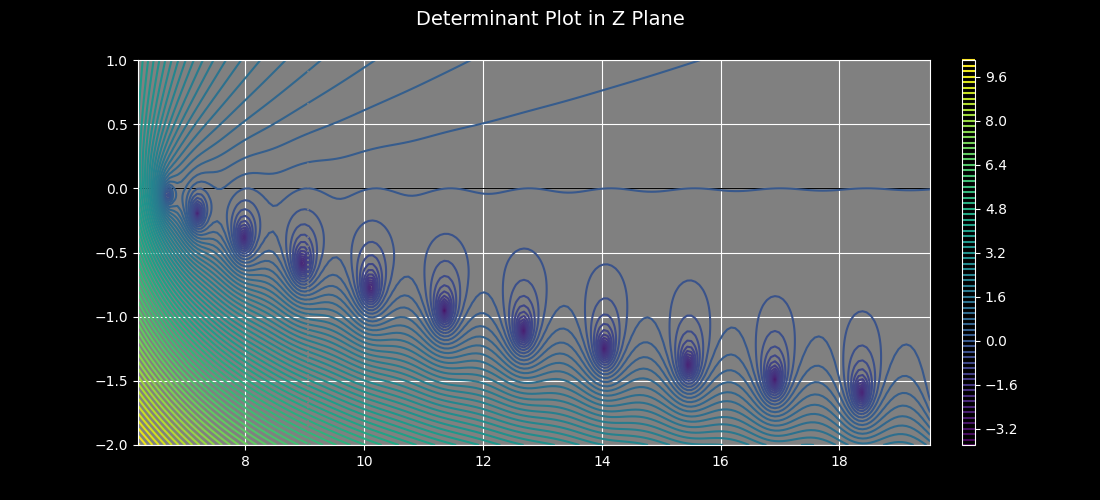

In [69]:
A.eigenvalue_plot(.95 * A.Z_hyperbolic, 3 * A.Z_hyperbolic, -2,1);

In [87]:
guesses = np.array(
    [
        6.7 -.1j,
        7.2-.2j,
        8-.4j,
        9-.6j,
        10-.8j,
        11.3-1j,
        # 13-1j,
        # 14-1.4j,
        # 15.5-1.4j,
        # 17-1.5j,
        # 18-1.6j,
    ]
)
Zs_leaky = np.array([newton(A.eigenvalues, guess) for guess in guesses])
A.plot_points(Zs_leaky)

In [88]:
Fs_leaky = [A.fields(Z, rounding=11) for Z in Zs_leaky]

In [89]:
coeffs = np.array([quad(lambda x: f0(x) * F(x), Lx, Rx, complex_func=True)[0] for F in Fs_leaky])

In [90]:
Leaky = lambda x,z: sum([c * F(x,z) for c,F in zip(coeffs, Fs_leaky)])

(-1.0, 1.875)

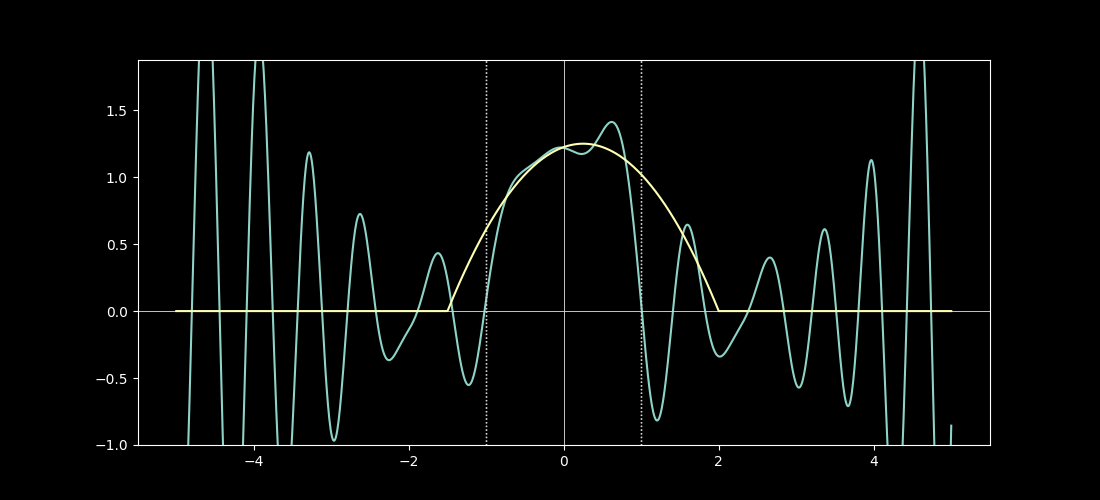

In [91]:
A.plot_field_1d(Leaky);
A.add_1d_plot(f0);
plt.gca().set_ylim(-1,1.5*amplitude)

(<Figure size 900x900 with 2 Axes>, <Axes: >)

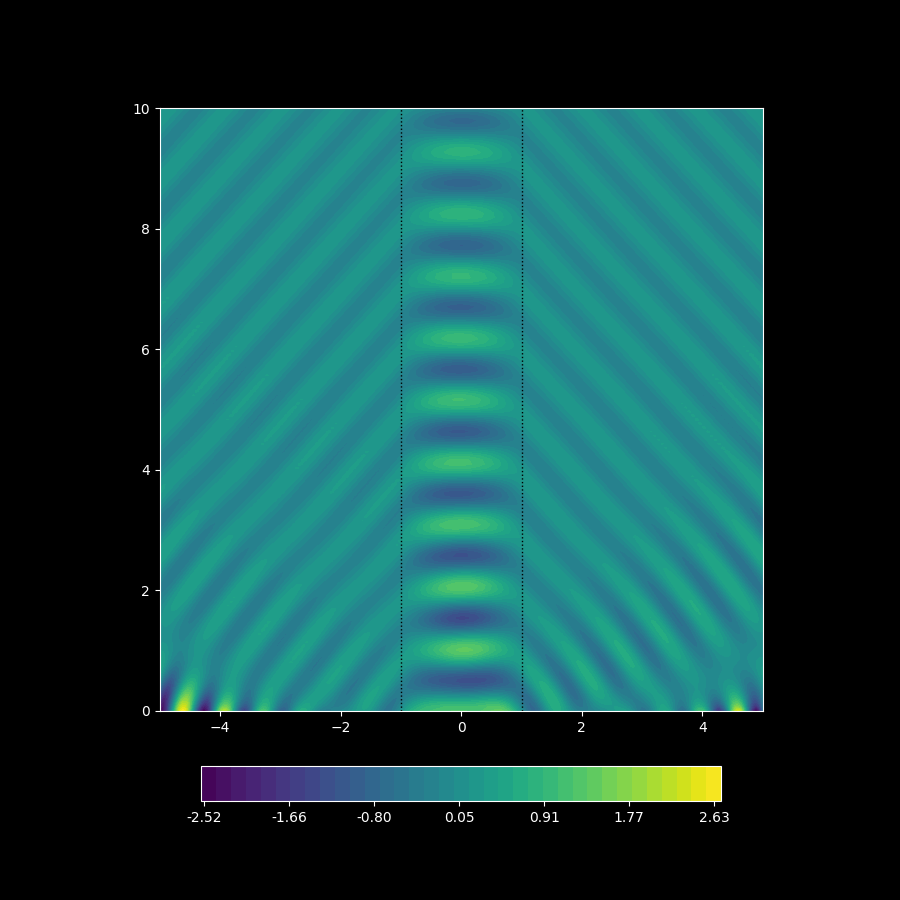

In [92]:
A.plot_field_2d(Leaky)

In [79]:
P.space_wave_approx(f0)

AttributeError: 'Slab' object has no attribute 'radiation_transform_dZ_approx'

## Animations

### Transverse field at input

In [ ]:
A.animate_field_1d(Leaky, 'leaky', xs=xs, linewidth=1.5, secs=2.5, fps=26, color='C0')

In [ ]:
Video('leaky.mp4', html_attributes="controls loop")


#### Full field

In [ ]:
A.animate_field_2d(Full, 'true_field_2d_animation', xs=xs, zs=np.linspace(0,10,100), secs=2.5, fps=26)

In [ ]:
A.animate_field_2d(Leaky, 'leaky_mode_antiguide_contour',xs=xs, zs=np.linspace(0,10,100), secs=2.5, fps=26)

In [ ]:
Video('true_field_2d_animation.mp4', html_attributes="controls loop autoplay")


In [ ]:
Video('leaky_mode_antiguide_contour.mp4', html_attributes="controls loop autoplay")


#### Animated surface plot

In [ ]:
# Slow animation cell
# A.animate_field_2d_surface(Full, 'true_field_3d_animation', fps=20, secs=2,
#                            xs=np.linspace(-6,6,120), zmin=0, zmax=10, zref=160,
#                            rstride=1, cstride=1, part='real',
#                            azim=-47, elev=30, zoom=3.5, dpi=120)

In [ ]:
# Slow animation cell# Slow animation cell
A.animate_field_2d_surface(Leaky, 'leaky_field_3d_animation', fps=20, secs=2,
                           xs=np.linspace(-6,6,120), zmin=0, zmax=10, zref=160,
                           rstride=1, cstride=1, part='real',
                           azim=-47, elev=30, zoom=3.5, dpi=120)

In [ ]:
HTML("""
<video controls id="theVideo3"> <source src="true_field_3d_animation.mp4"> </video>
<video controls id="theVideo4"> <source src="leaky_field_3d_animation.mp4"> </video>
<script> video3 = document.getElementById("theVideo3")
video4 = document.getElementById("theVideo4")
video3.width = 800; video3.playbackRate = 1; video3.loop = true; video3.autoplay = true;
video4.width = 800; video4.playbackRate = 1; video4.loop = true; video4.autoplay = true;
</script> """)


In [ ]:
def sdp(x, guide=A):
    K = guide.K0 * guide.n0
    return -(K * x) / np.sqrt(K**2 + x**2)

In [ ]:
xmin, xmax= -8, .5
ymin, ymax = -1, 2
xs_sdp = np.linspace(xmin, xmax, 1000)
ys_sdp = sdp(xs_sdp)
msk = np.where((ys_sdp<ymax)*(ys_sdp>ymin))

In [ ]:
plotlogf(A.determinant_Z, xmin, xmax, ymin, ymax, 'TE', 'leaky', iref=200, rref=200, levels=100)
ax = plt.gca()
ax.plot(xs_sdp[msk], ys_sdp[msk]);
# ax.plot(xs[msk], -ys[msk]);

In [ ]:
# propfuncs = [P1, P2, P3]
# evfuncs = [P4, P5, P6, P7, P8]

In [ ]:
# Prop = lambda x, z: sum([f.propagate(x, zs=z) for f in propfuncs])
# Ev = lambda x, z: sum([f.propagate(x, zs=z) for f in evfuncs]) 
# Full = lambda x, z: Prop(x, z) + Ev(x, z)

In [ ]:
xs = np.linspace(-15, 15, 1200)
zs = np.linspace(0, 20, 600)


In [ ]:
f0s = f0(xs)

In [ ]:
rad_ys_propagating = Prop(xs, zs)

In [ ]:
rad_ys_evanescent = Ev(xs, zs)


In [ ]:
Xs, Zs = np.meshgrid(xs, zs)

In [ ]:
def get_trig_indices(mesh_array):
    '''Get triangle index list for three js mesh formation via indexed buffer geometry.'''
    if len(mesh_array.shape) <= 1:
        raise ValueError('Provide meshgrid array as input.')
    Nz, Nx = mesh_array.shape[0], mesh_array.shape[1]
    l_inds = Nx * Nz
    indices =  np.arange(0, l_inds).reshape((Nx, Nz)).T  # Note transpose
    fbases = indices[:Nz-1, :Nx-1].T.flatten()  # Note transpose and index switch due to transpose
    f1 = np.array([[i, i+Nz, i+1] for i in fbases], dtype=int)
    f2 = np.array([[i+1, i+Nz, i+Nz+1] for i in fbases], dtype=int)
    return np.concatenate((f1, f2))


def get_base_vertices(Xs, Zs):
    '''Get vertices of triangles with zero height (y component in three.js).'''
    if Xs.shape != Zs.shape:
        raise ValueError('Provide meshgrid arrays (ie Xs, Zs = np.meshgrid(xs,zs)) as inputs.')
    Base = np.array([Xs, np.zeros_like(Xs), Zs], dtype=float)
    L = Xs.shape[0] * Xs.shape[1]
    base_vertices = Base.T.reshape((L,3))
    return base_vertices


def create_height_array_from_complex(ys, Xs):
    '''Get data for height from complex ys input (needs to be formatted as list:
        [ys[0].real, ys[0].imag, ys[1].real, ys[1].imag, ... ].'''
    L = Xs.shape[0] * Xs.shape[1]
    Ys = np.array([ys.real, ys.imag], dtype=float)
    heights = Ys.T.reshape((L,2))
    return heights


def save_trig_indices_as_json(filepath, mesh_array):
    indices = get_trig_indices(mesh_array)
    with open(filepath + '.json', 'w') as outfile:
        json.dump(indices.flatten().tolist(), outfile, separators=(',', ':'),
                  sort_keys=True, indent=4)


def save_base_vertices_as_json(filepath, Xs, Zs):
    base_vertices = get_base_vertices(Xs, Zs)
    with open(filepath + '.json', 'w') as outfile:
        json.dump(base_vertices.flatten().tolist(), outfile, separators=(',', ':'),
                  sort_keys=True, indent=4)
        

def save_heights_as_json(filepath, ys, Xs):
    heights= create_height_array_from_complex(ys, Xs)
    with open(filepath + '.json', 'w') as outfile:
        json.dump(heights.flatten().tolist(), outfile, separators=(',', ':'),
                  sort_keys=True, indent=4)

def save_values_as_json(filepath, f0s):
    with open(filepath + '.json', 'w') as outfile:
        json.dump(f0s.tolist(), outfile, separators=(',', ':'),
                  sort_keys=True, indent=4)




In [ ]:
prefix='/home/pv/local/slab/apps/antiguide/'

In [ ]:
save_trig_indices_as_json(prefix + 'trig_indices_new', Xs)


In [ ]:
save_base_vertices_as_json(prefix + 'base_vertices_new', Xs, Zs)


In [ ]:
save_heights_as_json(prefix + 'evanescent_heights', rad_ys_evanescent, Xs)


In [ ]:
save_heights_as_json(prefix + 'propagating_heights', rad_ys_propagating, Xs)


In [ ]:
save_values_as_json(prefix + 'f0s', f0s)


In [ ]:
save_values_as_json(prefix + 'x0s', xs)


### Our method

This still has issues: all the contour integrals go to zero.

In [ ]:
mode_type='leaky'

paper_method = False

In [ ]:
plotlogf(A.determinant_Z, - 1.4*A.K_low, -A.K_low, -1,1, field_type, mode_type,
         figsize=(10,5),iref=100, rref=100,levels=100)

hi kirbee ❤️

In [ ]:
Z_leaky = newton(A.determinant_Z, -6.5, args=('TE', mode_type))
Z_leaky, A.determinant_Z(Z_leaky, mode_type=mode_type)
plt.plot(Z_leaky.real, Z_leaky.imag, 'ro');

In [ ]:
circ_contour = {'center': Z_leaky, 'radius': 1e-4, 'N':50}

In [ ]:
P_leaky_even = Propagator_Class(f0=f0, Lx=-.5, Rx=.5, 
                     LZ=100, RZ=150, NZ=10, 
                     field_type=field_type, conjugate=False,
                     sign='+1', circ_contour=circ_contour, paper_method=paper_method)
P_leaky_odd = Propagator_Class(f0=f0, Lx=-.5, Rx=.5, 
                     LZ=100, RZ=150, NZ=10, 
                     field_type=field_type, conjugate=False,
                     sign='-1', circ_contour=circ_contour, paper_method=paper_method)

In [ ]:
plt.close('all')
fig, ax = plt.subplots(1, figsize=(8,4))
ax.plot(P_leaky_even.ts,  np.abs(P_leaky_even.alphas.imag));
ax.plot(P_leaky_odd.ts,  np.abs(P_leaky_odd.alphas));

In [ ]:
plt.close('all')
fig, ax = plt.subplots(1, figsize=(8,4))
ax.plot(P_leaky_even_theirs.ts,  np.abs(P_leaky_even_theirs.alphas.real));
ax.plot(P_leaky_odd_theirs.ts,  np.abs(P_leaky_odd_theirs.alphas));

In [ ]:
P_ls = [P_leaky_even, P_leaky_odd]

full_leaky = lambda x : sum([P.slice_propagate(x) for P in P_ls])
Full_leaky = lambda x, z : sum([P.propagate(x, zs=z) for P in P_ls])

In [ ]:
A.plot_field_1d(full_leaky, xs=xs, part='real', color='blue');

#### Asymptotics of true and leaky mode (found with contour integral)



In [ ]:
slice_at_x = 0
constant_variable = 'x'

full_z_leaky_ours = lambda z: sum([P.slice_propagate(z, slice_at=slice_at_x, constant_variable=constant_variable) for P in P_ls])
full_z = lambda z: sum([P.slice_propagate(z, slice_at=slice_at_x, constant_variable=constant_variable) for P in Ps])



In [ ]:
part = 'real'
A.plot_field_1d(full_z, xs=np.linspace(0, 13, 1000), part=part, plot_Rhos=False, linewidth=2,label='true');
A.add_1d_plot(full_z_leaky_ours, xs=np.linspace(0, 13, 1000), part=part, label='leaky ours');
A.add_1d_plot(full_z_leaky_theirs, xs=np.linspace(0, 13, 1000), part=part, linestyle='--', label='leaky theirs');


#### Issues:

- Using our method, even though there appears to be a pole in the integrand where we need it to be, when we do a circular contour integral it appears to zero out.  Everything should be right, but we get zero...  This happens for all other pole locations too: -Z, Z.conj(), -Z.conj().

- This is strange because when we do this for the delta function input everything works out: we get convergent leaky mode fields.


#### Seem to have found issue: We need to use non-conjugated version of expansion and orthogonality



## Adding steepest descent path contribution

In [ ]:
def sdp(x, guide=A):
    K = guide.K0 * guide.n0
    return -(K * x) / np.sqrt(K**2 + x**2)

In [ ]:
xmin, xmax= -8, .5
ymin, ymax = -1, 2
xs_sdp = np.linspace(xmin, xmax, 1000)
ys_sdp = sdp(xs_sdp)
msk = np.where((ys_sdp<ymax)*(ys_sdp>ymin))

In [ ]:
plotlogf(A.determinant_Z, xmin, xmax, ymin, ymax, 'TE', 'leaky', iref=200, rref=200, levels=100)
ax = plt.gca()
ax.plot(xs_sdp[msk], ys_sdp[msk]);
# ax.plot(xs[msk], -ys[msk]);